# Load the cleaned dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
file_path = "data/chicago_crime_cleaned.csv"

df = pd.read_csv(file_path)

df["DATE_OF_OCCURRENCE"] = pd.to_datetime(
    df["DATE_OF_OCCURRENCE"],
    errors="coerce"
)

print("Dataset loaded.")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Dataset loaded.
Rows: 228595
Columns: 17


# Check coordinates one final time

In [5]:
print("Missing latitude:", df["LATITUDE"].isna().sum())
print("Missing longitude:", df["LONGITUDE"].isna().sum())

print("\nLatitude range:")
print(df["LATITUDE"].min(), "to", df["LATITUDE"].max())

print("\nLongitude range:")
print(df["LONGITUDE"].min(), "to", df["LONGITUDE"].max())

Missing latitude: 0
Missing longitude: 0

Latitude range:
41.644589713 to 42.022547568

Longitude range:
-87.899493147 to -87.524529378


# Understand the 2.2 km grid

### "the entire urban area was divided into 2.2 x 2.2 km grid cells." stated in research paper

In [6]:
GRID_SIZE_KM = 2.2
GRID_SIZE_M = 2200

print("Grid size:", GRID_SIZE_KM, "km ×", GRID_SIZE_KM, "km")

Grid size: 2.2 km × 2.2 km


# Convert geographic coordinates to meters

In [ ]:
# !pip install pyproj

   ---------------------------------------- 0.0/6.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/6.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/6.3 MB ? eta -:--:--
   --- ------------------------------------ 0.5/6.3 MB 1.5 MB/s eta 0:00:04
   ---- ----------------------------------- 0.8/6.3 MB 1.3 MB/s eta 0:00:05
   ---- ----------------------------------- 0.8/6.3 MB 1.3 MB/s eta 0:00:05
   ---- ----------------------------------- 0.8/6.3 MB 1.3 MB/s eta 0:00:05
   ------ --------------------------------- 1.0/6.3 MB 774.8 kB/s eta 0:00:07
   ------ --------------------------------- 1.0/6.3 MB 774.8 kB/s eta 0:00:07
   -------- ------------------------------- 1.3/6.3 MB 762.6 kB/s eta 0:00:07
   --------- ------------------------------ 1.6/6.3 MB 777.0 kB/s eta 0:00:07
   --------- --------------------------


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
from pyproj import Transformer

# Convert WGS84 latitude/longitude to a metric projection
# EPSG:4326 = latitude/longitude
# EPSG:26916 = UTM Zone 16N, suitable for Chicago

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:26916",
    always_xy=True
)

x, y = transformer.transform(
    df["LONGITUDE"].values,
    df["LATITUDE"].values
)

df["GRID_X_M"] = x
df["GRID_Y_M"] = y

print(df[[
    "LATITUDE",
    "LONGITUDE",
    "GRID_X_M",
    "GRID_Y_M"
]].head())

    LATITUDE  LONGITUDE       GRID_X_M      GRID_Y_M
0  41.845527 -87.698757  441990.739717  4.632861e+06
1  41.766947 -87.576322  452096.495146  4.624062e+06
2  41.707346 -87.680037  443423.472159  4.617507e+06
3  41.930897 -87.697588  442164.830408  4.642339e+06
4  41.793687 -87.694105  442330.424984  4.627103e+06


# Find the grid origin

In [9]:
min_x = df["GRID_X_M"].min()
min_y = df["GRID_Y_M"].min()

print("Minimum projected X:", min_x)
print("Minimum projected Y:", min_y)

Minimum projected X: 425476.99038882746
Minimum projected Y: 4610479.474780203


# Assign every crime to a grid cell|

In [10]:
df["GRID_COL"] = np.floor(
    (df["GRID_X_M"] - min_x) / GRID_SIZE_M
).astype(int)

df["GRID_ROW"] = np.floor(
    (df["GRID_Y_M"] - min_y) / GRID_SIZE_M
).astype(int)

print(df[
    [
        "LATITUDE",
        "LONGITUDE",
        "GRID_ROW",
        "GRID_COL"
    ]
].head(10))

    LATITUDE  LONGITUDE  GRID_ROW  GRID_COL
0  41.845527 -87.698757        10         7
1  41.766947 -87.576322         6        12
2  41.707346 -87.680037         3         8
3  41.930897 -87.697588        14         7
4  41.793687 -87.694105         7         7
5  41.773085 -87.568335         6        12
6  41.808899 -87.643515         8         9
7  41.833364 -87.617008         9        10
8  41.747758 -87.652451         5         9
9  41.909664 -87.742729        13         5


# Create a unique Grid ID

In [11]:
df["GRID_ID"] = (
    df["GRID_ROW"].astype(str)
    + "_"
    + df["GRID_COL"].astype(str)
)

print(df[[
    "GRID_ROW",
    "GRID_COL",
    "GRID_ID"
]].head(10))

   GRID_ROW  GRID_COL GRID_ID
0        10         7    10_7
1         6        12    6_12
2         3         8     3_8
3        14         7    14_7
4         7         7     7_7
5         6        12    6_12
6         8         9     8_9
7         9        10    9_10
8         5         9     5_9
9        13         5    13_5


# Count the occupied grid cells

In [12]:
number_of_grid_cells = df["GRID_ID"].nunique()

print("Number of occupied grid cells:", number_of_grid_cells)

Number of occupied grid cells: 157


# Crime count per grid

In [13]:
grid_crime_counts = (
    df.groupby("GRID_ID")
    .size()
    .reset_index(name="CRIME_COUNT")
)

grid_crime_counts.head()

,GRID_ID,CRIME_COUNT
0,0_10,595
1,0_11,559
2,0_12,121
3,0_13,451
4,0_9,218


# Check the distribution

In [14]:
print("Grid crime count statistics:")
print(grid_crime_counts["CRIME_COUNT"].describe())

Grid crime count statistics:
count     157.000000
mean     1456.019108
std      1410.698979
min         1.000000
25%       279.000000
50%      1080.000000
75%      2376.000000
max      9549.000000
Name: CRIME_COUNT, dtype: float64


# Validate and Visualize the Grid

In [15]:
# Calculate the centroid of each occupied grid cell

grid_cells = (
    df.groupby(["GRID_ROW", "GRID_COL", "GRID_ID"])
    .agg(
        CENTROID_X_M=("GRID_X_M", "mean"),
        CENTROID_Y_M=("GRID_Y_M", "mean"),
        CRIME_COUNT=("CASE#", "count")
    )
    .reset_index()
)

print("Number of grid cells:", len(grid_cells))

display(grid_cells.head())

Number of grid cells: 157


,GRID_ROW,GRID_COL,GRID_ID,CENTROID_X_M,CENTROID_Y_M,CRIME_COUNT
0,0,9,0_9,446717.020829,4.612323e+06,218
1,0,10,0_10,449051.914996,4.611705e+06,595
2,0,11,0_11,450094.529327,4.611797e+06,559
3,0,12,0_12,453757.570368,4.611961e+06,121
4,0,13,0_13,454853.569451,4.611399e+06,451


# Convert centroids back to latitude/longitude

In [16]:
# Transformer for converting projected coordinates back to latitude/longitude

reverse_transformer = Transformer.from_crs(
    "EPSG:26916",
    "EPSG:4326",
    always_xy=True
)

centroid_lon, centroid_lat = reverse_transformer.transform(
    grid_cells["CENTROID_X_M"].values,
    grid_cells["CENTROID_Y_M"].values
)

grid_cells["CENTROID_LAT"] = centroid_lat
grid_cells["CENTROID_LON"] = centroid_lon

display(
    grid_cells[
        [
            "GRID_ID",
            "CENTROID_LAT",
            "CENTROID_LON",
            "CRIME_COUNT"
        ]
    ].head(10)
)

,GRID_ID,CENTROID_LAT,CENTROID_LON,CRIME_COUNT
0,0_9,41.660881,-87.639989,218
1,0_10,41.655463,-87.611893,595
2,0_11,41.656364,-87.599380,559
3,0_12,41.658058,-87.555400,121
4,0_13,41.653055,-87.542195,451
5,1_6,41.682279,-87.711016,2
6,1_7,41.680774,-87.697079,25
7,1_8,41.679786,-87.667214,441
8,1_9,41.675963,-87.641079,1332
9,1_10,41.676179,-87.622858,1181


# Check the centroid range

In [17]:
print("Centroid latitude range:")
print(
    grid_cells["CENTROID_LAT"].min(),
    "to",
    grid_cells["CENTROID_LAT"].max()
)

print("\nCentroid longitude range:")
print(
    grid_cells["CENTROID_LON"].min(),
    "to",
    grid_cells["CENTROID_LON"].max()
)

Centroid latitude range:
41.65305545311851 to 42.02174004604961

Centroid longitude range:
-87.892058358 to -87.52487321184853


# Visualize the grid cells

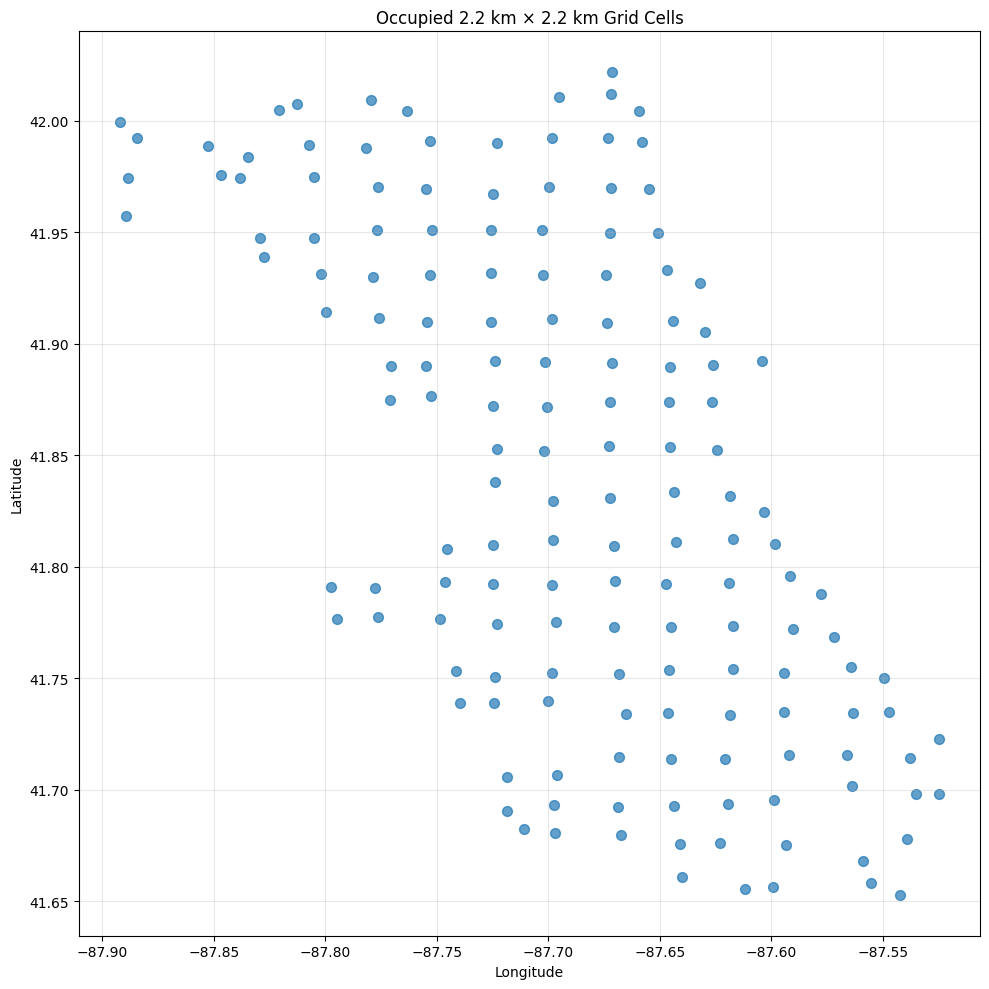

In [18]:
plt.figure(figsize=(10, 10))

plt.scatter(
    grid_cells["CENTROID_LON"],
    grid_cells["CENTROID_LAT"],
    s=50,
    alpha=0.7
)

plt.title("Occupied 2.2 km × 2.2 km Grid Cells")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Show crime intensity on the grid

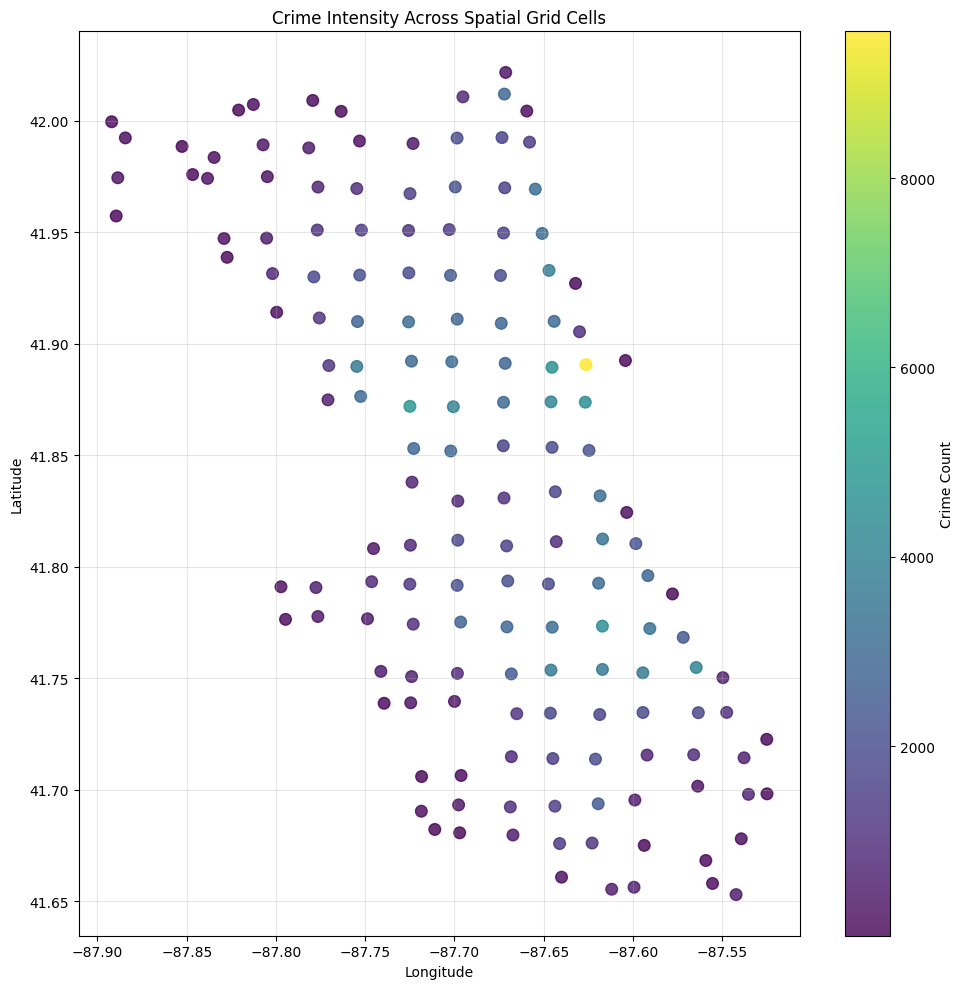

In [19]:
plt.figure(figsize=(10, 10))

scatter = plt.scatter(
    grid_cells["CENTROID_LON"],
    grid_cells["CENTROID_LAT"],
    c=grid_cells["CRIME_COUNT"],
    s=70,
    alpha=0.8
)

plt.colorbar(scatter, label="Crime Count")

plt.title("Crime Intensity Across Spatial Grid Cells")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Identify the highest-crime grid cells

In [20]:
top_grid_cells = (
    grid_cells
    .sort_values("CRIME_COUNT", ascending=False)
    .head(20)
)

display(
    top_grid_cells[
        [
            "GRID_ID",
            "CENTROID_LAT",
            "CENTROID_LON",
            "CRIME_COUNT"
        ]
    ]
)

,GRID_ID,CENTROID_LAT,CENTROID_LON,CRIME_COUNT
100,12_10,41.890726,-87.626262,9549
89,11_6,41.872014,-87.724974,4868
99,12_9,41.889506,-87.645350,4586
93,11_10,41.873865,-87.626694,4467
56,6_10,41.773454,-87.617101,4464
92,11_9,41.874013,-87.645916,4044
90,11_7,41.871830,-87.700646,3967
47,5_12,41.754914,-87.564548,3960
117,14_9,41.932978,-87.647018,3810
44,5_9,41.753740,-87.645930,3651


# Calculate percentage of crimes in the top 10 cells

In [21]:
top_10_crimes = (
    grid_cells
    .nlargest(10, "CRIME_COUNT")["CRIME_COUNT"]
    .sum()
)

total_crimes = len(df)

top_10_percentage = (
    top_10_crimes / total_crimes * 100
)

print("Crimes in top 10 grid cells:", top_10_crimes)
print(
    f"Percentage of all crimes in top 10 grid cells: "
    f"{top_10_percentage:.2f}%"
)

Crimes in top 10 grid cells: 47366
Percentage of all crimes in top 10 grid cells: 20.72%


# Calculate the actual grid-cell centroid

In [22]:
# Calculate the actual geometric center of each 2.2 km grid cell

grid_cells["GRID_CENTER_X_M"] = (
    min_x + (grid_cells["GRID_COL"] + 0.5) * GRID_SIZE_M
)

grid_cells["GRID_CENTER_Y_M"] = (
    min_y + (grid_cells["GRID_ROW"] + 0.5) * GRID_SIZE_M
)

print("Grid centroids calculated.")

Grid centroids calculated.


# Convert the actual centroids to latitude/longitude

In [23]:
grid_center_lon, grid_center_lat = reverse_transformer.transform(
    grid_cells["GRID_CENTER_X_M"].values,
    grid_cells["GRID_CENTER_Y_M"].values
)

grid_cells["GRID_CENTER_LAT"] = grid_center_lat
grid_cells["GRID_CENTER_LON"] = grid_center_lon

display(
    grid_cells[
        [
            "GRID_ID",
            "GRID_ROW",
            "GRID_COL",
            "GRID_CENTER_LAT",
            "GRID_CENTER_LON",
            "CRIME_COUNT"
        ]
    ].head(10)
)

,GRID_ID,GRID_ROW,GRID_COL,GRID_CENTER_LAT,GRID_CENTER_LON,CRIME_COUNT
0,0_9,0,9,41.654160,-87.644006,218
1,0_10,0,10,41.654305,-87.617586,595
2,0_11,0,11,41.654444,-87.591166,559
3,0_12,0,12,41.654577,-87.564745,121
4,0_13,0,13,41.654704,-87.538324,451
5,1_6,1,6,41.673503,-87.723487,2
6,1_7,1,7,41.673666,-87.697060,25
7,1_8,1,8,41.673823,-87.670632,441
8,1_9,1,9,41.673975,-87.644204,1332
9,1_10,1,10,41.674120,-87.617775,1181


# Check grid size

In [24]:
# Check the distance between two adjacent grid columns
# using the projected coordinates

sample = grid_cells[
    (grid_cells["GRID_ROW"] == grid_cells["GRID_ROW"].min())
].sort_values("GRID_COL")

if len(sample) >= 2:
    x1 = sample.iloc[0]["GRID_CENTER_X_M"]
    x2 = sample.iloc[1]["GRID_CENTER_X_M"]

    distance_km = abs(x2 - x1) / 1000

    print(
        f"Distance between adjacent grid centers: "
        f"{distance_km:.2f} km"
    )

Distance between adjacent grid centers: 2.20 km


# Final grid visualization

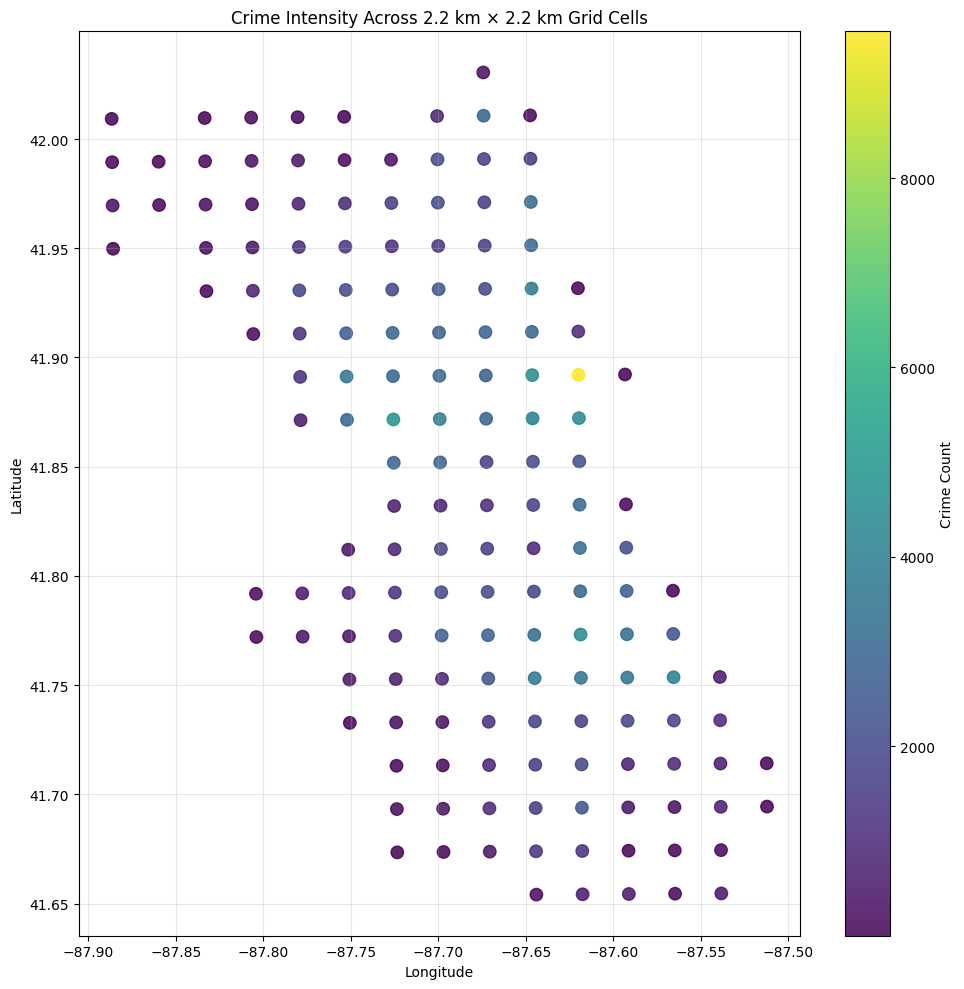

In [25]:
plt.figure(figsize=(10, 10))

scatter = plt.scatter(
    grid_cells["GRID_CENTER_LON"],
    grid_cells["GRID_CENTER_LAT"],
    c=grid_cells["CRIME_COUNT"],
    s=80,
    alpha=0.85
)

plt.colorbar(scatter, label="Crime Count")

plt.title("Crime Intensity Across 2.2 km × 2.2 km Grid Cells")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Create the final node table

In [26]:
grid_nodes = grid_cells[
    [
        "GRID_ID",
        "GRID_ROW",
        "GRID_COL",
        "GRID_CENTER_LAT",
        "GRID_CENTER_LON",
        "CRIME_COUNT"
    ]
].copy()

print("Final number of graph nodes:", len(grid_nodes))

display(grid_nodes.head(10))

Final number of graph nodes: 157


,GRID_ID,GRID_ROW,GRID_COL,GRID_CENTER_LAT,GRID_CENTER_LON,CRIME_COUNT
0,0_9,0,9,41.654160,-87.644006,218
1,0_10,0,10,41.654305,-87.617586,595
2,0_11,0,11,41.654444,-87.591166,559
3,0_12,0,12,41.654577,-87.564745,121
4,0_13,0,13,41.654704,-87.538324,451
5,1_6,1,6,41.673503,-87.723487,2
6,1_7,1,7,41.673666,-87.697060,25
7,1_8,1,8,41.673823,-87.670632,441
8,1_9,1,9,41.673975,-87.644204,1332
9,1_10,1,10,41.674120,-87.617775,1181


# Save the grid

In [27]:
grid_file = "data/chicago_spatial_grid.csv"

grid_nodes.to_csv(
    grid_file,
    index=False
)

print("Spatial grid saved to:")
print(grid_file)

Spatial grid saved to:
data/chicago_spatial_grid.csv


In [28]:
test_grid = pd.read_csv(grid_file)

print("Grid file loaded successfully.")
print("Number of nodes:", len(test_grid))
print("Number of columns:", len(test_grid.columns))

Grid file loaded successfully.
Number of nodes: 157
Number of columns: 6
